In [25]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import math
import autoroot
from paper_plots.plot_config import set_plot_style

from src.utils.result_processing import MODEL_KEY_REGISTRY


font_size = 55
legend_font_size = 40
lw=4
figsize = (12,8)

# Apply consistent styling
set_plot_style(font_family='Times New Roman', font_size=font_size, figsize=figsize, palette='Spectral',legend_font_size=legend_font_size)
# loss = 'val/rLoss1_epoch'
loss = 'train/rLoss1_epoch.min'

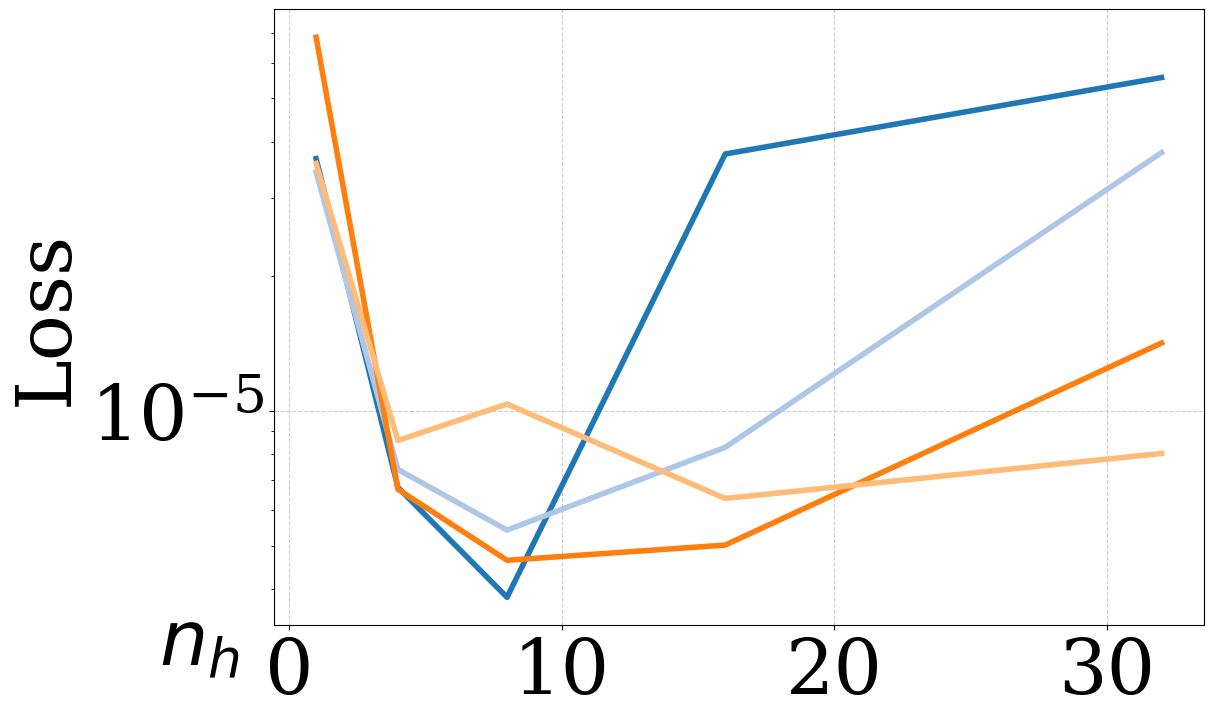

In [26]:
m_key_1 = MODEL_KEY_REGISTRY['Trans_hid_dim']
m_key_2 = MODEL_KEY_REGISTRY['Trans_nhead']
df = pd.read_pickle(f"../../results/Transformer_exponential_experiment_data_clean.pkl")
df['m_1'] = df[m_key_1]
df['m_2'] = df[m_key_2]
df['alpha'] = df['data.rho_param.alpha']/df['data.rho_param.alpha'].max()
df_min = df.groupby(['m_1', 'm_2', 'alpha'], as_index=False)[loss].min()
df_min = df_min[df_min['alpha']==df_min['alpha'].max()]


fig, ax1 = plt.subplots(figsize=figsize)

# Plot the original lines
palette = sns.color_palette('tab20', n_colors=df_min['m_1'].nunique())
sns.lineplot(data=df_min, x='m_2', y=loss, hue='m_1', ax=ax1,
             palette=palette, lw=lw, legend=False)


ax1.set_xlabel(r'$n_h$')
ax1.xaxis.set_label_coords(-0.08, 0.03)
ax1.set_yscale('log')
ax1.set_ylabel('Loss')
plt.savefig('Transformer_exp.pdf', bbox_inches='tight')

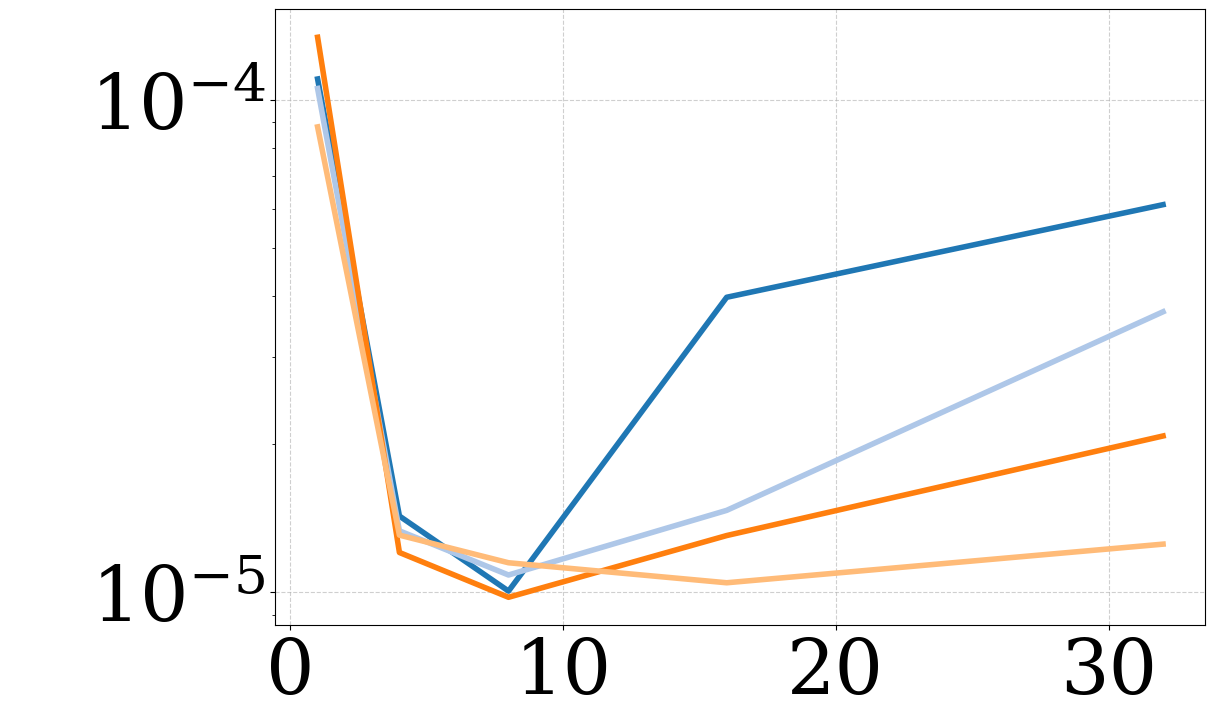

In [27]:
m_key_1 = MODEL_KEY_REGISTRY['Trans_hid_dim']
m_key_2 = MODEL_KEY_REGISTRY['Trans_nhead']
df = pd.read_pickle(f"../../results/Transformer_polynomial_experiment_data_clean.pkl")
df['m_1'] = df[m_key_1]
df['m_2'] = df[m_key_2]
df['alpha'] = df['data.rho_param.alpha']/df['data.rho_param.alpha'].max()
df_min = df.groupby(['m_1', 'm_2', 'alpha'], as_index=False)[loss].min()
df_min = df_min[df_min['alpha']==df_min['alpha'].max()]


fig, ax1 = plt.subplots(figsize=figsize)

# Plot the original lines
palette = sns.color_palette('tab20', n_colors=df_min['m_1'].nunique())
sns.lineplot(data=df_min, x='m_2', y=loss, hue='m_1', ax=ax1,
             palette=palette, lw=lw, legend=False)


ax1.set_xlabel(r'')
ax1.xaxis.set_label_coords(-0.08, 0.03)
ax1.set_yscale('log')
ax1.set_ylabel(' ')
plt.savefig('Transformer_poly.pdf', bbox_inches='tight')

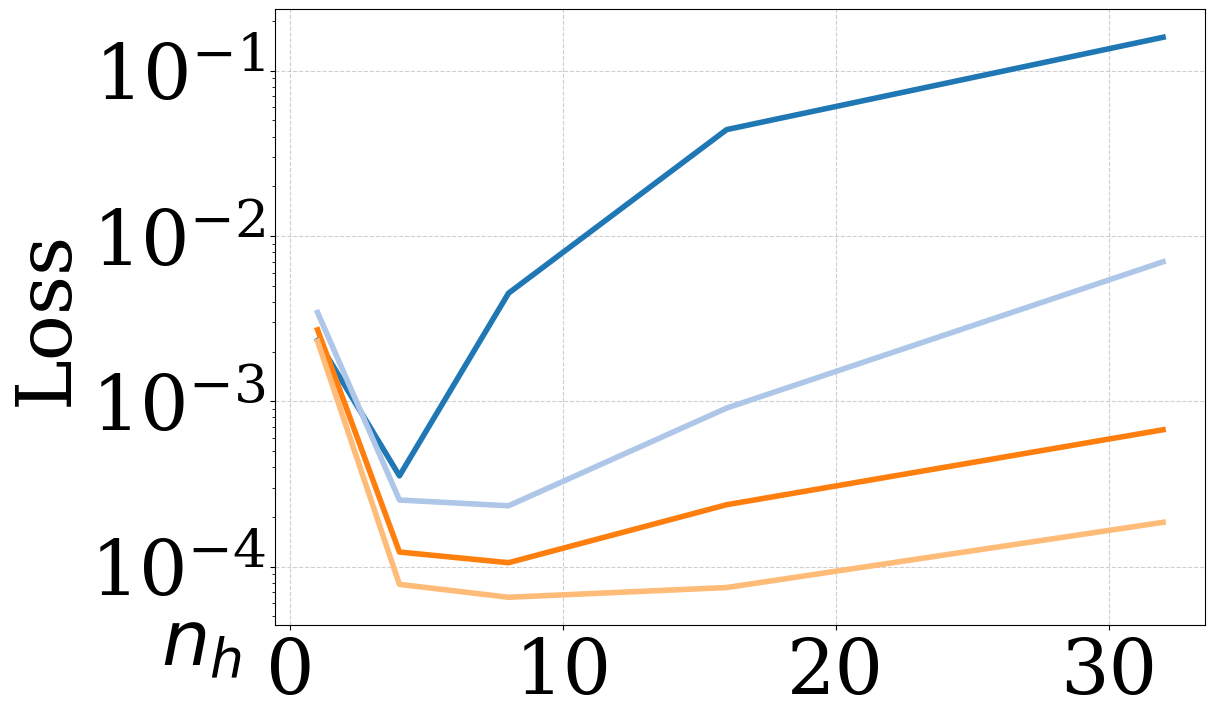

In [28]:
m_key_1 = MODEL_KEY_REGISTRY['Trans_hid_dim']
m_key_2 = MODEL_KEY_REGISTRY['Trans_nhead']
df = pd.read_pickle(f"../../results/Transformer_impulse_experiment_data_clean.pkl")
df['m_1'] = df[m_key_1]
df['m_2'] = df[m_key_2]
df['alpha'] = df['data.rho_param.alpha']/df['data.rho_param.alpha'].max()
df_min = df.groupby(['m_1', 'm_2', 'alpha'], as_index=False)[loss].min()
df_min = df_min[df_min['alpha']==df_min['alpha'].max()]

fig, ax1 = plt.subplots(figsize=figsize)

# Plot the original lines
palette = sns.color_palette('tab20', n_colors=df_min['m_1'].nunique())
sns.lineplot(data=df_min, x='m_2', y=loss, hue='m_1', ax=ax1,
             palette=palette, lw=lw, legend=False)

ax1.set_xlabel(r'$n_h$')
ax1.xaxis.set_label_coords(-0.08, 0.03)
ax1.set_yscale('log')
ax1.set_ylabel('Loss')
plt.savefig('Transformer_impulse.pdf', bbox_inches='tight')

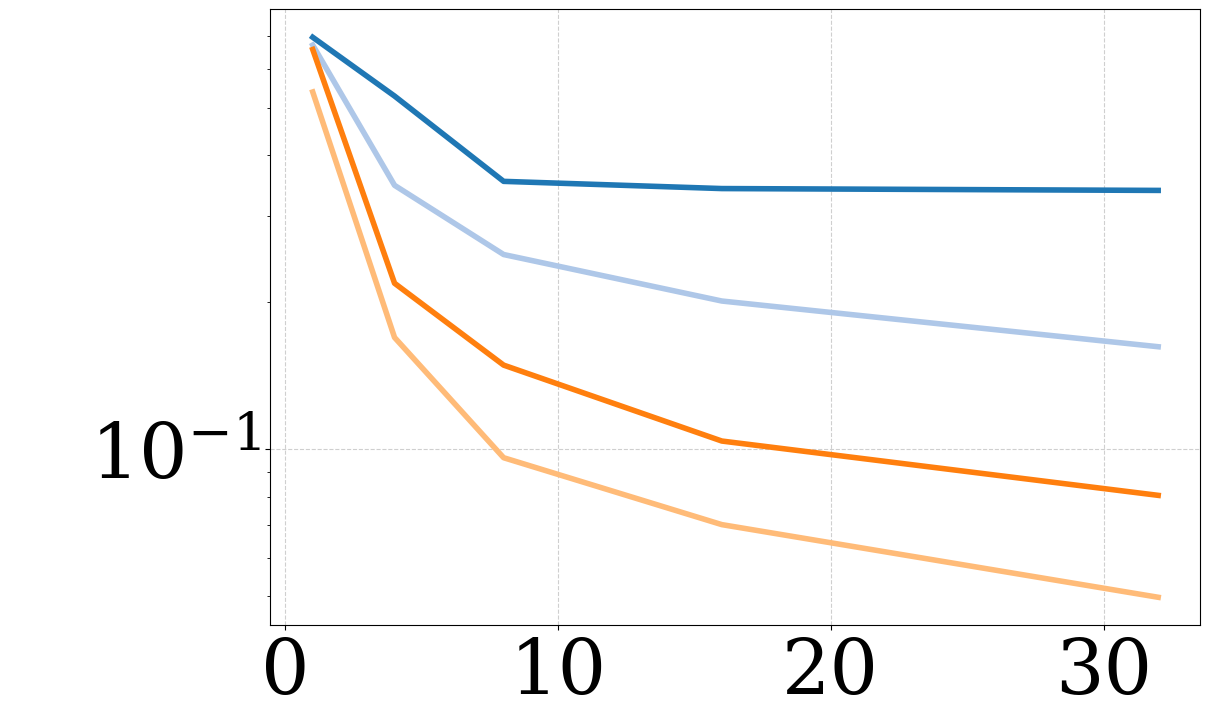

In [29]:
m_key_1 = MODEL_KEY_REGISTRY['Trans_hid_dim']
m_key_2 = MODEL_KEY_REGISTRY['Trans_nhead']
df = pd.read_pickle(f"../../results/Transformer_airy_experiment_data_clean.pkl")
df['m_1'] = df[m_key_1]
df['m_2'] = df[m_key_2]
df['alpha'] = df['data.rho_param.alpha']/df['data.rho_param.alpha'].max()
df_min = df.groupby(['m_1', 'm_2', 'alpha'], as_index=False)[loss].min()
df_min = df_min[df_min['alpha']==df_min['alpha'].max()]


fig, ax1 = plt.subplots(figsize=figsize)

# Plot the original lines
palette = sns.color_palette('tab20', n_colors=df_min['m_1'].nunique())
sns.lineplot(data=df_min, x='m_2', y=loss, hue='m_1', ax=ax1,
             palette=palette, lw=lw, legend=False)


ax1.set_xlabel(r'')
ax1.xaxis.set_label_coords(-0.08, 0.03)
ax1.set_yscale('log')
ax1.set_ylabel(' ')
plt.savefig('Transformer_airy.pdf', bbox_inches='tight')

## -----------------

/tmp/ipykernel_1271597/4037342495.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_min = df.groupby(['m_1', 'm_2', 'alpha'], as_index=False)[loss].min()


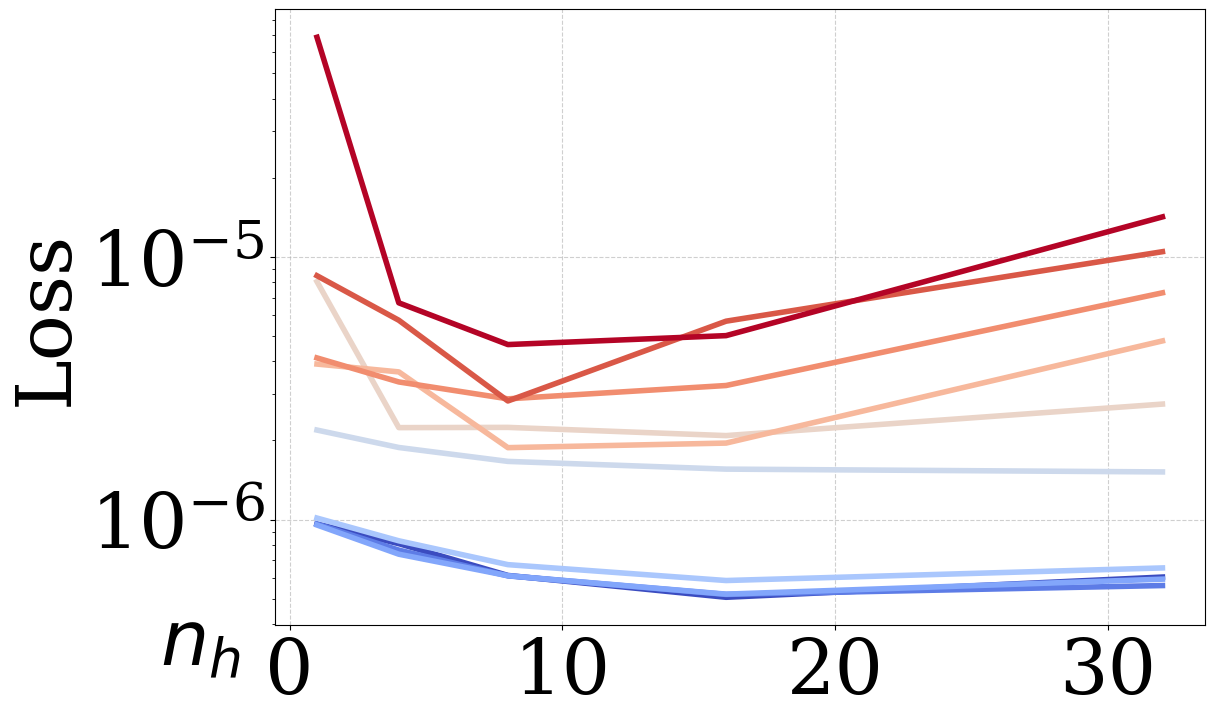

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Load and preprocess data
m_key_1 = MODEL_KEY_REGISTRY['Trans_hid_dim']
m_key_2 = MODEL_KEY_REGISTRY['Trans_nhead']
df = pd.read_pickle("../../results/Transformer_exponential_experiment_data_clean.pkl")
df['m_1'] = df[m_key_1]
df['m_2'] = df[m_key_2]
df['alpha'] = pd.Categorical(df['data.rho_param.alpha'] / df['data.rho_param.alpha'].max())
df_min = df.groupby(['m_1', 'm_2', 'alpha'], as_index=False)[loss].min()
df_min = df_min[df_min['m_1'] == 128]

# Create color map for categorical 'alpha'
cmap = plt.cm.coolwarm
norm = mcolors.BoundaryNorm(boundaries=range(len(df_min['alpha'].cat.categories) + 1), ncolors=len(df_min['alpha'].cat.categories))

fig, ax1 = plt.subplots(figsize=figsize)

# Plot each alpha category as a separate line
for i, alpha_level in enumerate(df_min['alpha'].cat.categories):
    subset = df_min[df_min['alpha'] == alpha_level]
    color = cmap(i / (len(df_min['alpha'].cat.categories) - 1))
    sns.lineplot(data=subset, x='m_2', y=loss, ax=ax1, 
                 color=color, linewidth=lw, label=str(alpha_level), legend=False)

ax1.set_xlabel(r'$n_h$')
ax1.set_ylabel('Loss')
ax1.set_yscale('log')
ax1.xaxis.set_label_coords(-0.08, 0.03)

plt.savefig('Transformer_exp_alpha.pdf', bbox_inches='tight')
plt.show()

/tmp/ipykernel_1271597/3455028980.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_min = df.groupby(['m_1', 'm_2', 'alpha'], as_index=False)[loss].min()


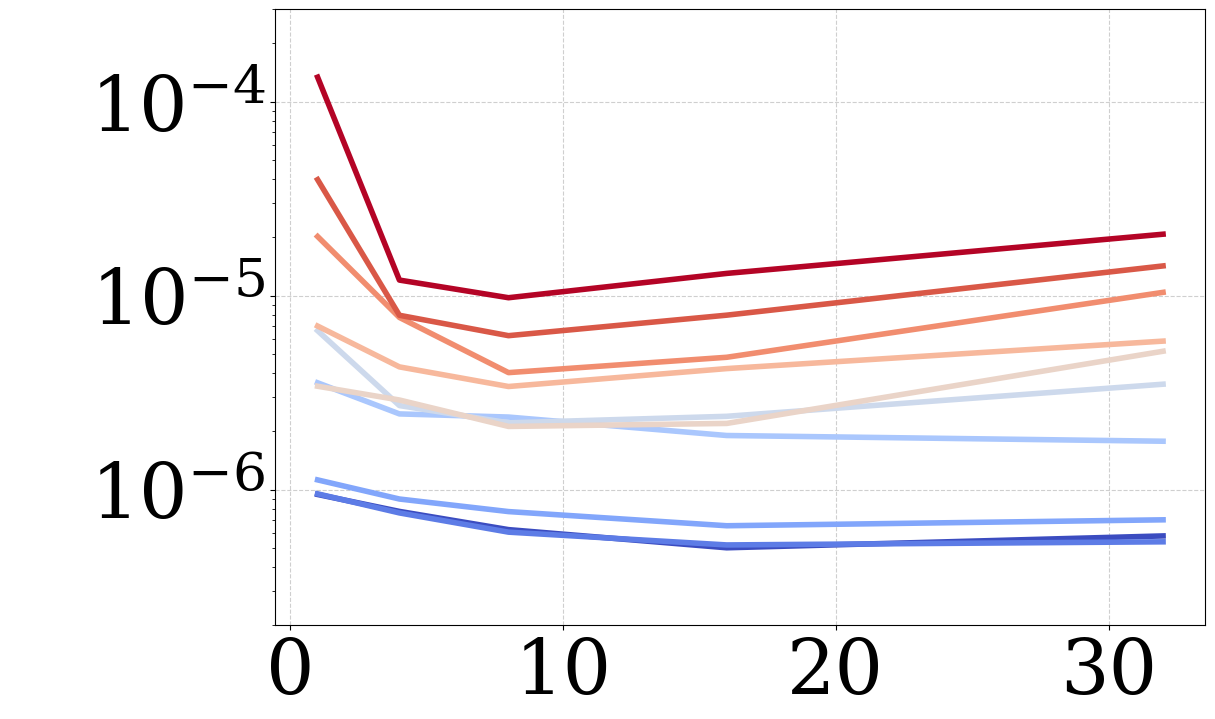

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Load and preprocess data
m_key_1 = MODEL_KEY_REGISTRY['Trans_hid_dim']
m_key_2 = MODEL_KEY_REGISTRY['Trans_nhead']
df = pd.read_pickle("../../results/Transformer_polynomial_experiment_data_clean.pkl")
df['m_1'] = df[m_key_1]
df['m_2'] = df[m_key_2]
df['alpha'] = pd.Categorical(df['data.rho_param.alpha'] / df['data.rho_param.alpha'].max())
df_min = df.groupby(['m_1', 'm_2', 'alpha'], as_index=False)[loss].min()
df_min = df_min[df_min['m_1'] == 128]

# Create color map for categorical 'alpha'
cmap = plt.cm.coolwarm
norm = mcolors.BoundaryNorm(boundaries=range(len(df_min['alpha'].cat.categories) + 1), ncolors=len(df_min['alpha'].cat.categories))

fig, ax1 = plt.subplots(figsize=figsize)

# Plot each alpha category as a separate line
for i, alpha_level in enumerate(df_min['alpha'].cat.categories):
    subset = df_min[df_min['alpha'] == alpha_level]
    color = cmap(i / (len(df_min['alpha'].cat.categories) - 1))
    sns.lineplot(data=subset, x='m_2', y=loss, ax=ax1, 
                 color=color, linewidth=lw, label=str(alpha_level), legend=False)

ax1.set_xlabel(r'')
ax1.set_ylabel(' ')
ax1.set_yscale('log')
ax1.xaxis.set_label_coords(-0.08, 0.03)
ax1.set_ylim(2*1e-7,3*1e-4)
plt.savefig('Transformer_poly_alpha.pdf', bbox_inches='tight')
plt.show()

/tmp/ipykernel_1271597/925800706.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_min = df.groupby(['m_1', 'm_2', 'alpha'], as_index=False)[loss].min()


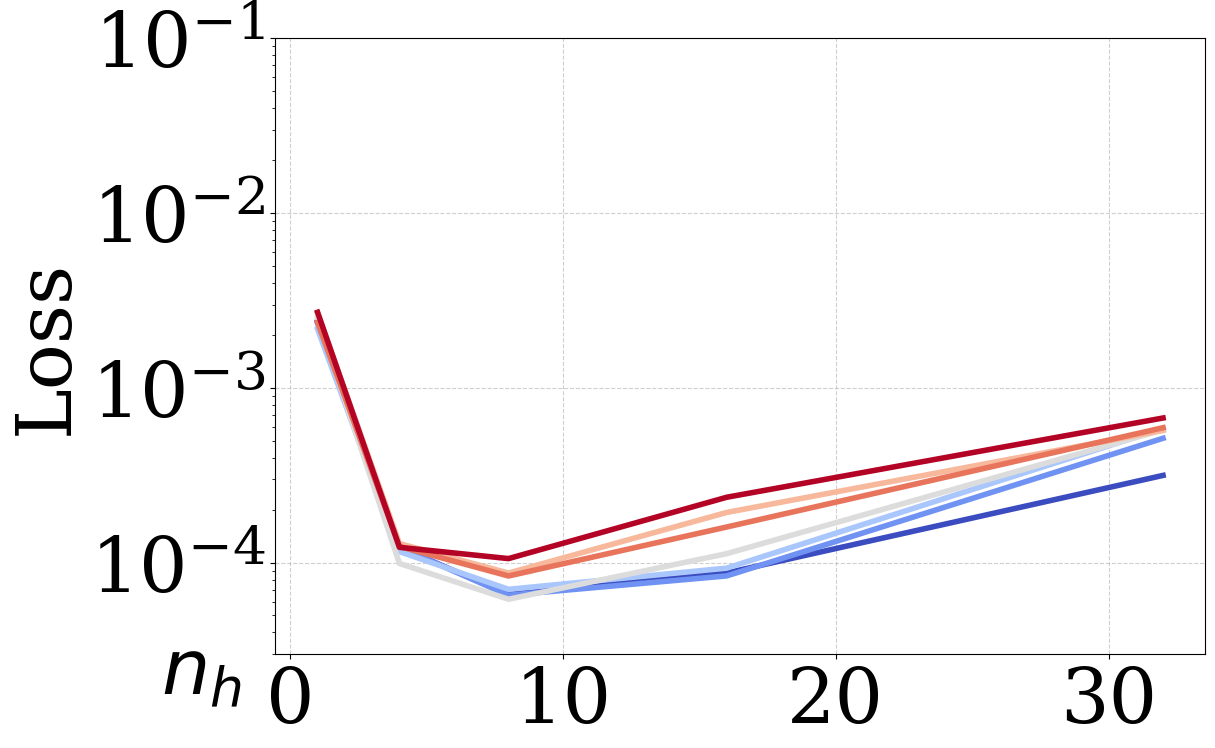

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Load and preprocess data
m_key_1 = MODEL_KEY_REGISTRY['Trans_hid_dim']
m_key_2 = MODEL_KEY_REGISTRY['Trans_nhead']
df = pd.read_pickle("../../results/Transformer_impulse_experiment_data_clean.pkl")
df['m_1'] = df[m_key_1]
df['m_2'] = df[m_key_2]
df = df[df['data.rho_param.alpha'] > 0.01]
df['alpha'] = pd.Categorical(df['data.rho_param.alpha'] / df['data.rho_param.alpha'].max())
df_min = df.groupby(['m_1', 'm_2', 'alpha'], as_index=False)[loss].min()
df_min = df_min[df_min['m_1'] == 128]


# Create color map for categorical 'alpha'
cmap = plt.cm.coolwarm
norm = mcolors.BoundaryNorm(boundaries=range(len(df_min['alpha'].cat.categories) + 1), ncolors=len(df_min['alpha'].cat.categories))

fig, ax1 = plt.subplots(figsize=figsize)

# Plot each alpha category as a separate line
for i, alpha_level in enumerate(df_min['alpha'].cat.categories):
    subset = df_min[df_min['alpha'] == alpha_level]
    color = cmap(i / (len(df_min['alpha'].cat.categories) - 1))
    sns.lineplot(data=subset, x='m_2', y=loss, ax=ax1, 
                 color=color, linewidth=lw, label=str(alpha_level), legend=False)

ax1.set_xlabel(r'$n_h$')
ax1.set_ylabel('Loss')
ax1.set_yscale('log')
ax1.xaxis.set_label_coords(-0.08, 0.03)
ax1.set_ylim(3*1e-5, 1e-1)
plt.savefig('Transformer_impulse_alpha.pdf', bbox_inches='tight')
plt.show()

/tmp/ipykernel_1271597/2523106575.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_min = df.groupby(['m_1', 'm_2', 'alpha'], as_index=False)[loss].min()


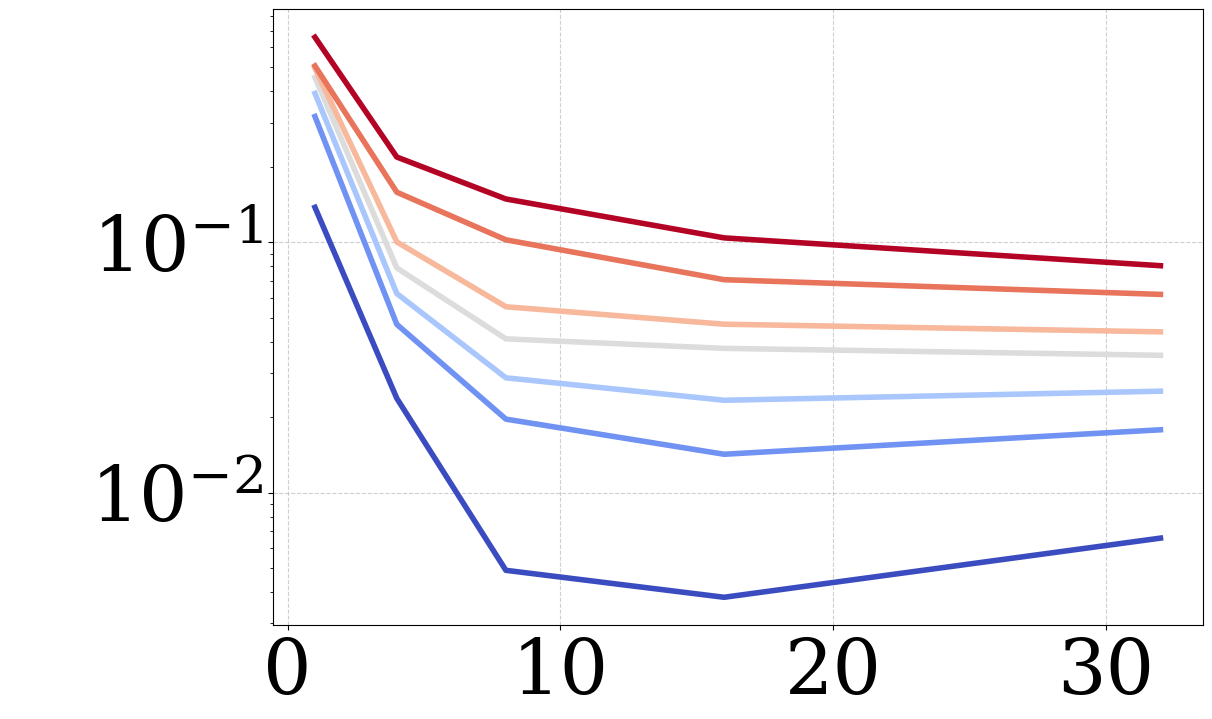

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Load and preprocess data
m_key_1 = MODEL_KEY_REGISTRY['Trans_hid_dim']
m_key_2 = MODEL_KEY_REGISTRY['Trans_nhead']
df = pd.read_pickle("../../results/Transformer_airy_experiment_data_clean.pkl")
df['m_1'] = df[m_key_1]
df['m_2'] = df[m_key_2]
df = df[df['data.rho_param.alpha'] > 0.01]
df['alpha'] = pd.Categorical(df['data.rho_param.alpha'] / df['data.rho_param.alpha'].max())
df_min = df.groupby(['m_1', 'm_2', 'alpha'], as_index=False)[loss].min()
df_min = df_min[df_min['m_1'] == 128]


# Create color map for categorical 'alpha'
cmap = plt.cm.coolwarm
norm = mcolors.BoundaryNorm(boundaries=range(len(df_min['alpha'].cat.categories) + 1), ncolors=len(df_min['alpha'].cat.categories))

fig, ax1 = plt.subplots(figsize=figsize)


# Plot each alpha category as a separate line
for i, alpha_level in enumerate(df_min['alpha'].cat.categories):
    subset = df_min[df_min['alpha'] == alpha_level]
    color = cmap(i / (len(df_min['alpha'].cat.categories) - 1))
    sns.lineplot(data=subset, x='m_2', y=loss, ax=ax1, 
                 color=color, linewidth=lw, label=str(alpha_level), legend=False)

ax1.set_xlabel(r'')
ax1.set_ylabel(' ')
ax1.set_yscale('log')
ax1.xaxis.set_label_coords(-0.08, 0.03)
plt.savefig('Transformer_airy_alpha.pdf', bbox_inches='tight')
plt.show()

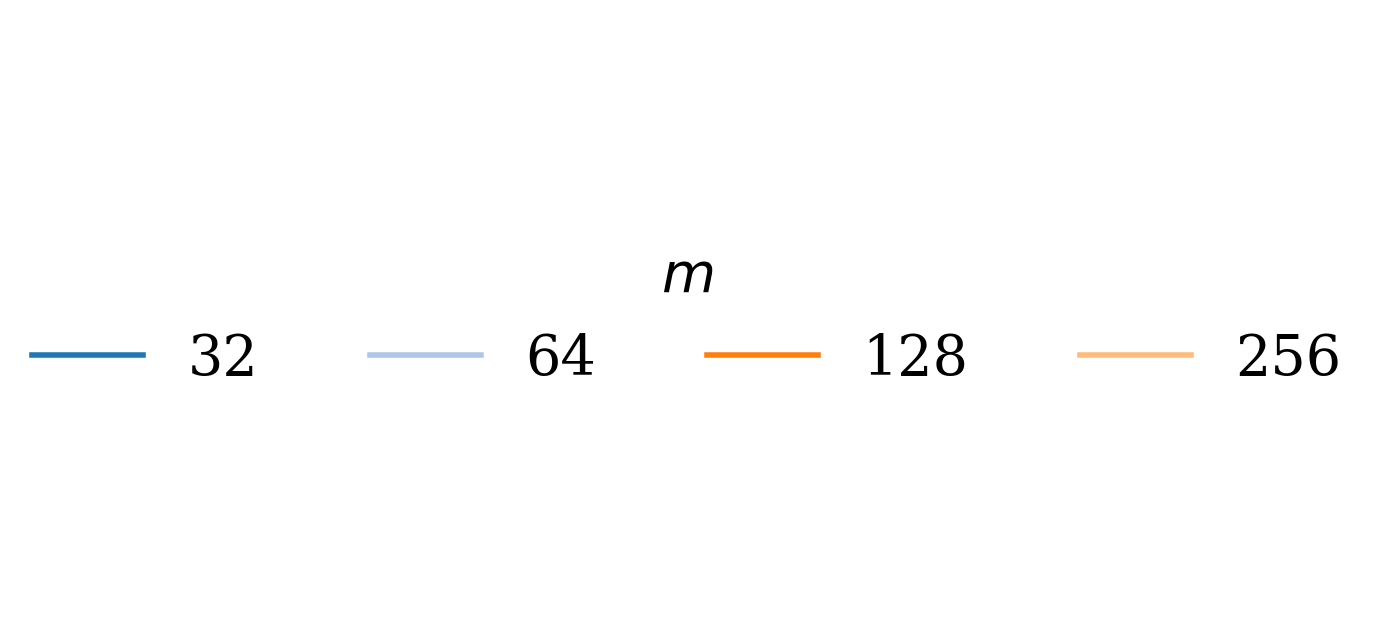

In [34]:
# Create a plot with just the legend
m_key_1 = MODEL_KEY_REGISTRY['Trans_hid_dim']
m_key_2 = MODEL_KEY_REGISTRY['Trans_nhead']
df = pd.read_pickle(f"../../results/Transformer_exponential_experiment_data_clean.pkl")
df['m_1'] = df[m_key_1]
df['m_2'] = df[m_key_2]
df['alpha'] = df['data.rho_param.alpha']/df['data.rho_param.alpha'].max()
df_min = df.groupby(['m_1', 'm_2', 'alpha'], as_index=False)[loss].min()
df_min = df_min[df_min['alpha']==df_min['alpha'].max()]

fig, ax_legend = plt.subplots(figsize=figsize)
# Create the plot to get the legend handles
line_plot = sns.lineplot(data=df_min, x='m_2', y=loss, hue='m_1', ax=ax_legend,
             palette='tab20', lw=lw)

# Get handles and labels
handles, labels = ax_legend.get_legend_handles_labels()

# Clear the axis
ax_legend.clear()
ax_legend.axis('off')

# Create legend only
legend = ax_legend.legend(handles, labels, title=r'$m$', loc='center', 
                          ncol=4, frameon=False)

plt.savefig('Transformer_legend.pdf', bbox_inches='tight')

/tmp/ipykernel_1271597/4162430075.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_min = df.groupby(['m_1', 'm_2', 'alpha'], as_index=False)[loss].min()


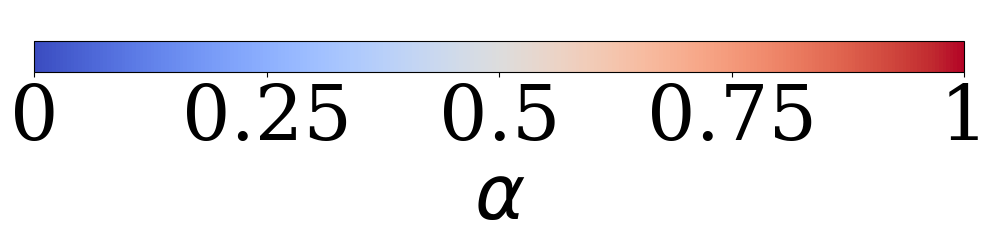

In [43]:
# Create a plot with just the colorbar for alpha plots
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Load data to get alpha categories (using polynomial as reference)
m_key_1 = MODEL_KEY_REGISTRY['Trans_hid_dim']
m_key_2 = MODEL_KEY_REGISTRY['Trans_nhead']
df = pd.read_pickle("../../results/Transformer_impulse_experiment_data_clean.pkl")
df['m_1'] = df[m_key_1]
df['m_2'] = df[m_key_2]
df['alpha'] = pd.Categorical(df['data.rho_param.alpha'] / df['data.rho_param.alpha'].max())
df_min = df.groupby(['m_1', 'm_2', 'alpha'], as_index=False)[loss].min()

# Create color map
cmap = plt.cm.coolwarm
norm = mcolors.Normalize(vmin=0, vmax=1)

# Create figure for colorbar only
fig, ax_cbar = plt.subplots(figsize=(figsize[0], 2))
ax_cbar.axis('off')

# Create scalar mappable for colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

# Create horizontal colorbar
cbar = plt.colorbar(sm, ax=ax_cbar, orientation='horizontal', 
                    fraction=0.8, aspect=30)
cbar.set_label(r'$\alpha$', fontsize=font_size)

# Set tick labels to show actual alpha values
alpha_values = sorted([float(alpha) for alpha in df_min['alpha'].cat.categories])
cbar.set_ticks([0,0.25, 0.5,0.75, 1])
cbar.set_ticklabels([f"0", f"0.25", f"0.5", f"0.75", f"1"])

plt.savefig('Transformer_colorbar.pdf', bbox_inches='tight')
plt.show()